# AI651 Assignment 3 — LargeST-SD Spatio-Temporal Forecasting (Q3–Q7)

Run this notebook **top to bottom**; later sections reuse objects from earlier ones.

| Section | Assignment part |
|---|---|
| 1. Setup | Q7 (seed, hyperparameters) |
| 2. Data + resampling + missing values | Q3(a) |
| 3. Graph construction | Q3(b), Q3(c) |
| 4. Windows, splits, normalisation | Q4(a) |
| 5. Model (temporal encoder, GCN, head) | Q4(b) |
| 6. Training / evaluation harness | Q4(b), Q7 |
| 7. Experiments: temporal-only, fixed, adaptive, hybrid | Q4(c), Q5(a–c) |
| 8. Results table and prediction plots | Q6(a) |
| 9. Learned-graph analysis | Q6(b) |
| 10. Reproducibility info | Q7 |

**Before you start**
1. Download LargeST from Kaggle and put the files in `DATA_DIR` (default `./data/ca`):
   `ca_meta.csv`, `ca_rn_adj.npy`, `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5` (file names are set in the loader; adjust them if yours differ).
2. `pip install numpy pandas matplotlib torch tables` (`tables` is needed by `pd.read_hdf`).
3. To smoke-test the whole notebook in a few minutes without the dataset, set the environment variable `NB_SYNTHETIC=1` (and e.g. `NB_EPOCHS=2`) before launching Jupyter. **Never report synthetic numbers.**

## 1. Setup and configuration

In [13]:
import os, time, json, platform, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------------- configuration (all hyperparameters live here) ----------------
SEED        = 42
DATA_DIR    = os.environ.get("LARGEST_DIR", "./data/ca")
SYNTHETIC   = os.environ.get("NB_SYNTHETIC", "0") == "1"   # smoke-test mode only
AGG         = "sum"        # "sum" (interval vehicle counts) or "mean" (flow rates) -- see Q3(a)
FFILL_LIMIT = 4            # forward-fill gaps of up to 4 steps (1 hour); the rest -> train-set mean

HIST, HORIZON = 8, 4       # 8 inputs (2 h) -> 4 outputs (1 h)
HIDDEN      = 32           # d in the assignment (16-32)
EMB_DIM     = 16           # d_e for adaptive adjacency
TOPK        = 20           # top-k neighbours kept per node in the adaptive graph (None = dense)
HYBRID_ALPHA       = 0.5
HYBRID_LEARN_ALPHA = False
BATCH       = 128
EPOCHS      = int(os.environ.get("NB_EPOCHS", 10))
LR          = 1e-3
PATIENCE    = 3            # early stopping on validation MAE
MAX_BATCHES = int(os.environ.get("NB_MAX_BATCHES", 0)) or None   # debug: cap batches/epoch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("device:", device, "| synthetic:", SYNTHETIC, "| aggregation:", AGG)

device: cpu | synthetic: False | aggregation: sum


## 2. Q3(a) — Extraction, resampling, missing values

**Aggregation choice.** LargeST flow comes from Caltrans PeMS, where each 5-minute value is the *number of vehicles that passed in that 5-minute interval* (an interval count, not an hourly rate). To keep physical units (vehicles per 15 min) we **sum** three 5-min values. Confirm this against the LargeST/PeMS documentation and write your justification in the report; if you decide the values are rates, set `AGG = "mean"`.

The loader assumes the layout of the official repo: `ca_meta.csv` (columns `ID, Lat, Lng, District, ...`), `ca_rn_adj.npy` (adjacency over all 8,600 sensors, same row order as the meta file), and `ca_his_raw_<year>.h5` (rows = 5-min timestamps, columns = sensor IDs). The SD subset is District 11 (716 sensors). **If an assertion below fails, inspect your files and adapt the loader.**

In [14]:
import os, glob

# 1) see what Kaggle actually mounted
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "|", files[:20])

# 2) locate ca_meta.csv and set DATA_DIR directly (overrides the default)
hits = glob.glob("/kaggle/input/**/ca_meta.csv", recursive=True)
print("found:", hits)
assert hits, "ca_meta.csv not found - paste the listing above and I'll adapt the loader"
DATA_DIR = os.path.dirname(hits[0])
print("DATA_DIR =", DATA_DIR)

/kaggle/input | []
/kaggle/input/datasets | []
/kaggle/input/datasets/liuxu77 | []
/kaggle/input/datasets/liuxu77/largest | ['ca_his_raw_2017.h5', 'ca_his_raw_2018.h5', 'ca_his_raw_2019.h5', 'ca_his_raw_2020.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_rn_adj.npy']
found: ['/kaggle/input/datasets/liuxu77/largest/ca_meta.csv']
DATA_DIR = /kaggle/input/datasets/liuxu77/largest


In [15]:
def make_synthetic(N=100, seed=0):
    """Fake 5-min data with daily/weekly structure + a chain graph. Smoke-test only."""
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2020-01-01", "2021-12-31 23:55", freq="5min")
    tod = ((idx.hour * 60 + idx.minute) / 1440).values[:, None]
    dow = idx.dayofweek.values[:, None]
    pos = np.linspace(0, 1, N)[None, :]
    daily = 1 + 0.8 * np.sin(2 * np.pi * (tod - 0.15 * pos - 0.25))
    flow = 30 * daily * np.where(dow >= 5, 0.7, 1.0) * (0.5 + pos) + rng.normal(0, 3, (len(idx), N))
    flow = np.clip(flow, 0, None)
    flow[rng.random(flow.shape) < 0.01] = np.nan
    ids = [str(1000 + i) for i in range(N)]
    df = pd.DataFrame(flow.astype(np.float32), index=idx, columns=ids)
    d = np.abs(np.arange(N)[:, None] - np.arange(N)[None, :])
    A = np.where((d > 0) & (d <= 3), np.exp(-(d ** 2) / 4.0), 0.0).astype(np.float32)
    meta = pd.DataFrame({"ID": ids, "Lat": 32.5 + 0.2 * pos[0], "Lng": -117.2 + 0.1 * pos[0]})
    return df, A, meta

import gc

def load_largest_sd():
    meta = pd.read_csv(os.path.join(DATA_DIR, "ca_meta.csv"))
    meta["orig_row"] = meta.index
    sd = meta[meta["District"] == 11].reset_index(drop=True)

    adj_path = glob.glob(os.path.join(DATA_DIR, "**", "*adj*.npy"), recursive=True)[0]
    A_full = np.load(adj_path, mmap_mode="r")          # avoids loading the full matrix into RAM
    rows = sd["orig_row"].values
    A = np.asarray(A_full[np.ix_(rows, rows)])
    del A_full

    cols = sd["ID"].astype(str).tolist()
    parts = []
    for y in (2020, 2021):
        f = glob.glob(os.path.join(DATA_DIR, "**", f"*{y}*.h5"), recursive=True)
        print(y, "->", f)
        d = pd.read_hdf(f[0])
        d.columns = d.columns.astype(str)
        parts.append(d[cols].astype("float32"))
        del d; gc.collect()
    return pd.concat(parts), A, sd

raw_df, A_raw, meta = make_synthetic() if SYNTHETIC else load_largest_sd()
N = raw_df.shape[1]
assert A_raw.shape == (N, N)
assert list(raw_df.columns) == meta["ID"].astype(str).tolist(), "sensor order mismatch"
if not SYNTHETIC: assert N == 716, f"expected 716 SD sensors, got {N}"
print("sensors:", N, "| raw rows:", len(raw_df), "|", raw_df.index.min(), "->", raw_df.index.max())
raw_df = raw_df[(raw_df.index >= "2020-01-01") & (raw_df.index < "2022-01-01")]

# ---- missing-value report on the raw 5-min data ----
print(f"raw NaN fraction : {raw_df.isna().mean().mean():.4%}")
print(f"raw zero fraction: {(raw_df == 0).mean().mean():.4%}  (zeros may be true no-traffic or sensor outage)")

2020 -> ['/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2020.h5']
2021 -> ['/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2021.h5']
sensors: 716 | raw rows: 210528 | 2020-01-01 00:00:00 -> 2021-12-31 23:55:00
raw NaN fraction : 5.0662%
raw zero fraction: 0.2667%  (zeros may be true no-traffic or sensor outage)


In [16]:
# ---- resample 5 min -> 15 min ----
full_idx = pd.date_range("2020-01-01", "2021-12-31 23:45", freq="15min")
if AGG == "sum":
    df15 = raw_df.resample("15min").sum(min_count=3)   # NaN unless all 3 five-minute values exist
else:
    df15 = raw_df.resample("15min").mean()
df15 = df15.reindex(full_idx)                          # missing timestamps become NaN rows

n_nan = int(df15.isna().sum().sum())
print(f"after resampling: {df15.shape}, NaN cells: {n_nan} ({n_nan / df15.size:.4%})")

# ---- missing-value handling (leak-free) ----
# 1) forward-fill short gaps (uses only PAST values, so no future information)
# 2) remaining gaps -> per-sensor mean computed on TRAINING rows only (2020)
train_rows = full_idx < "2021-01-01"
train_sensor_mean = df15[train_rows].mean()
df15 = df15.ffill(limit=FFILL_LIMIT).fillna(train_sensor_mean).fillna(0.0)
assert not df15.isna().any().any()
print("NaNs after handling:", int(df15.isna().sum().sum()))

after resampling: (70176, 716), NaN cells: 2550289 (5.0756%)
NaNs after handling: 0


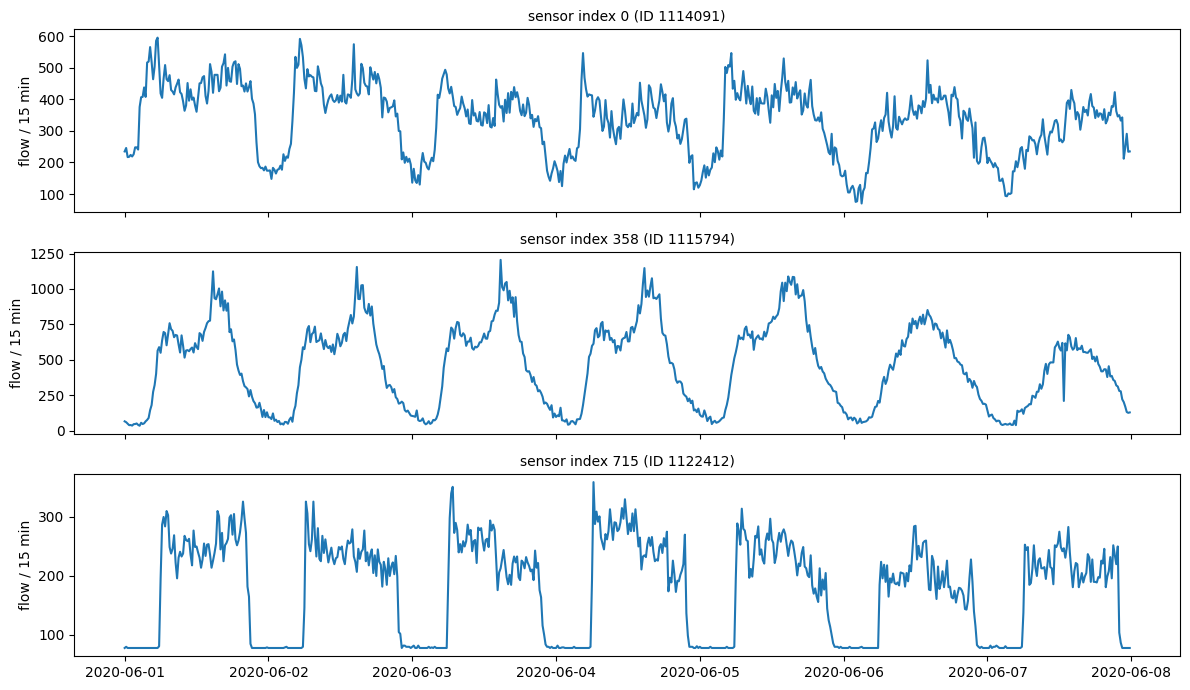

In [17]:
# ---- plot three sensors over one week (Mon 2020-06-01 .. Sun 2020-06-07) ----
sensor_ids = [0, N // 2, N - 1]
week = df15.loc["2020-06-01":"2020-06-07 23:45"]
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for a, s in zip(ax, sensor_ids):
    a.plot(week.index, week.iloc[:, s]); a.set_ylabel("flow / 15 min")
    a.set_title(f"sensor index {s} (ID {df15.columns[s]})", fontsize=10)
plt.tight_layout(); plt.show()

## 3. Q3(b) — Traffic graph

The adjacency was sliced with the same row indices used to select the traffic columns, so row *i* of `A_raw` ↔ column *i* of `df15` (asserted above via the meta table).

nodes: 716
nonzero entries (incl. diagonal): 18035 | diagonal nonzeros: 716
nonzero off-diagonal edges (directed count): 17319
symmetric: False
fraction of edges whose reverse edge is absent: 0.21427334141694093
weight range of nonzero entries: 0.01000183541327715 - 1.0


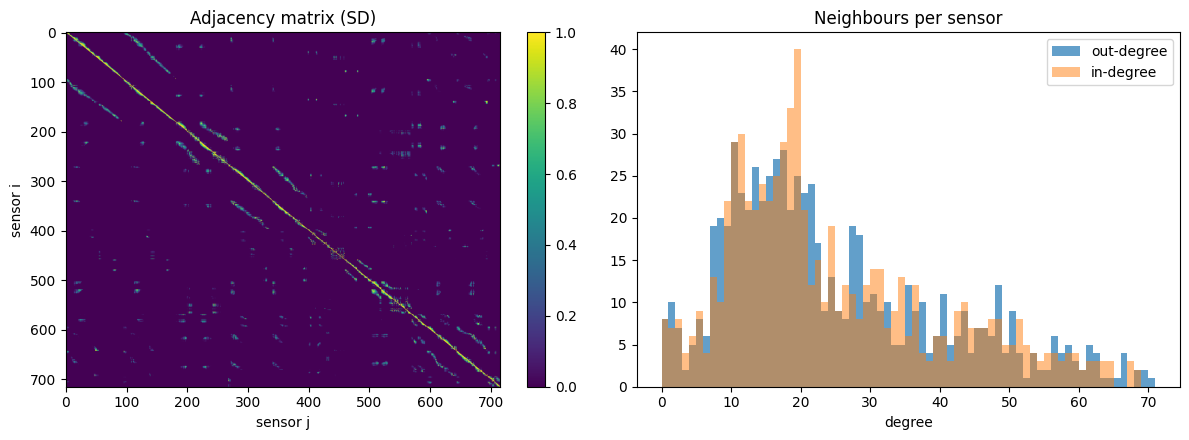

degree: min 0, median 20.0, mean 24.19, max 70, isolated nodes 8


In [18]:
A = np.asarray(A_raw, dtype=np.float32)
diag_nnz = int((np.diag(A) != 0).sum())
off = A.copy(); np.fill_diagonal(off, 0)
print("nodes:", A.shape[0])
print("nonzero entries (incl. diagonal):", int((A != 0).sum()), "| diagonal nonzeros:", diag_nnz)
print("nonzero off-diagonal edges (directed count):", int((off != 0).sum()))
sym = np.allclose(A, A.T)
print("symmetric:", sym)
if not sym:
    print("fraction of edges whose reverse edge is absent:",
          float(((off != 0) & (off.T == 0)).sum() / max((off != 0).sum(), 1)))
print("weight range of nonzero entries:", float(A[A != 0].min()), "-", float(A.max()))

A_bin = (off > 0).astype(np.int64)
out_deg, in_deg = A_bin.sum(1), A_bin.sum(0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
im = ax[0].imshow(A, cmap="viridis", aspect="auto"); ax[0].set_title("Adjacency matrix (SD)")
ax[0].set_xlabel("sensor j"); ax[0].set_ylabel("sensor i"); plt.colorbar(im, ax=ax[0])
ax[1].hist(out_deg, bins=range(0, int(out_deg.max()) + 2), alpha=0.7, label="out-degree")
if not sym: ax[1].hist(in_deg, bins=range(0, int(in_deg.max()) + 2), alpha=0.5, label="in-degree")
ax[1].set_title("Neighbours per sensor"); ax[1].set_xlabel("degree"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"degree: min {out_deg.min()}, median {np.median(out_deg)}, mean {out_deg.mean():.2f}, max {out_deg.max()}, isolated nodes {(out_deg == 0).sum()}")

**Explain in the report:** what a nonzero $A_{ij}$ means (a road-distance relationship between sensors *i* and *j*; with a Gaussian kernel the value decays with distance, and zeros mean the distance exceeded the threshold). Use the printed statistics for the symmetry/degree discussion.

## 3b. Q3(c) — One-hop and two-hop neighbourhoods

sensor 33: one-hop = 20, within two hops = 73, exactly two hops = 53
one-hop neighbours: [34, 35, 36, 37, 125, 126, 127, 128, 129, 130, 131, 181, 184, 185, 186, 187, 188, 221, 222, 223]


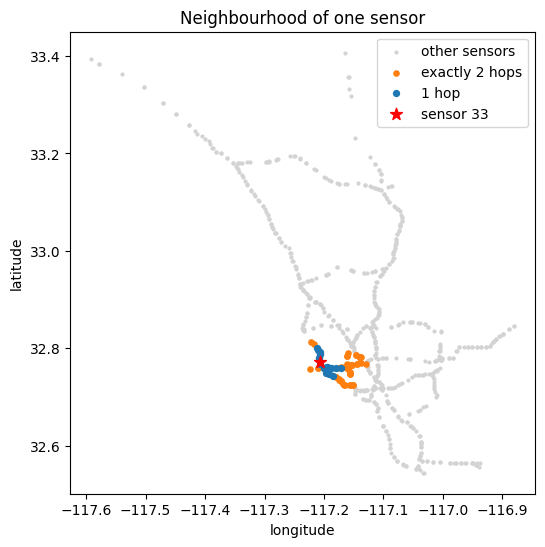

In [19]:
i = int(np.argsort(out_deg)[N // 2])                    # a median-degree sensor
one_hop = np.flatnonzero(A_bin[i])
reach2 = (A_bin + A_bin @ A_bin) > 0                    # paths of length 1 or 2
reach2[np.arange(N), np.arange(N)] = False
two_hop_all = np.flatnonzero(reach2[i])                 # "at most two edges"
exactly_two = np.setdiff1d(two_hop_all, one_hop)
print(f"sensor {i}: one-hop = {len(one_hop)}, within two hops = {len(two_hop_all)}, exactly two hops = {len(exactly_two)}")
print("one-hop neighbours:", one_hop.tolist())

if {"Lat", "Lng"} <= set(meta.columns):
    plt.figure(figsize=(6, 6))
    plt.scatter(meta["Lng"], meta["Lat"], s=4, c="lightgray", label="other sensors")
    plt.scatter(meta["Lng"][exactly_two], meta["Lat"][exactly_two], s=14, c="tab:orange", label="exactly 2 hops")
    plt.scatter(meta["Lng"][one_hop], meta["Lat"][one_hop], s=18, c="tab:blue", label="1 hop")
    plt.scatter(meta["Lng"][i], meta["Lat"][i], s=80, c="red", marker="*", label=f"sensor {i}")
    plt.legend(); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("Neighbourhood of one sensor"); plt.show()

**Write in the report (own words):** why neighbours help (congestion propagates along roads); one-hop = direct neighbours only, two-hop = information that has passed through an intermediate sensor (larger receptive field, a smoother mix); and over-smoothing — with many GCN layers (or many powers of $\hat A$) node representations converge toward similar values and local detail is lost, which can hurt accuracy.

## 4. Q4(a) — Windows, chronological splits, normalisation

* Train: Jan–Dec 2020, Val: Jan–Mar 2021, Test: Apr–Dec 2021.
* A window with last-input index *t* uses inputs `t-7..t` and targets `t+1..t+4`. All 12 timestamps must lie inside the **same** split, so windows never straddle a boundary.
* Normalisation uses the mean/std of the **training rows only** (a single global scalar pair).

In [20]:
times = df15.index
T = len(times)
e_tr = int((times < "2021-01-01").sum())
e_va = int((times < "2021-04-01").sum())
bounds = {"train": (0, e_tr), "val": (e_tr, e_va), "test": (e_va, T)}   # half-open [lo, hi)

def window_ends(lo, hi):
    """All t with inputs t-HIST+1..t and targets t+1..t+HORIZON inside [lo, hi)."""
    return np.arange(lo + HIST - 1, hi - HORIZON)

MU = float(df15.values[:e_tr].mean())
SD = float(df15.values[:e_tr].std())
data_n = torch.tensor((df15.values - MU) / SD, dtype=torch.float32)       # (T, N)
print(f"train mean {MU:.2f}, std {SD:.2f}")

OFF_IN, OFF_OUT = torch.arange(-HIST + 1, 1), torch.arange(1, HORIZON + 1)
def get_batch(t_idx):
    t = torch.as_tensor(np.asarray(t_idx))
    return data_n[t[:, None] + OFF_IN], data_n[t[:, None] + OFF_OUT]       # (B,8,N), (B,4,N)

for name, (lo, hi) in bounds.items():
    ts = window_ends(lo, hi)
    assert ts.min() - (HIST - 1) >= lo and ts.max() + HORIZON < hi        # no boundary crossing
    print(f"{name:5s}: {times[lo].date()} .. {times[hi-1].date()} | {len(ts)} windows")
xb, yb = get_batch(window_ends(*bounds["train"])[:2]); print("sample shapes:", tuple(xb.shape), tuple(yb.shape))

train mean 588.54, std 484.96
train: 2020-01-01 .. 2020-12-31 | 35125 windows
val  : 2021-01-01 .. 2021-03-31 | 8629 windows
test : 2021-04-01 .. 2021-12-31 | 26389 windows
sample shapes: (2, 8, 716) (2, 4, 716)


## 5. Q4(b) — Model

`TemporalEncoder` (two 1-D convs over the 8 time steps of each sensor, shared across sensors) → `Z ∈ R^{B×N×d}` → graph convolution `H = ReLU(Â Z W)` → MLP head → `Ŷ ∈ R^{B×4×N}`.

Adjacency modes: `none` (temporal-only baseline), `fixed`, `adaptive`, `hybrid`.

**Adaptive graph / sparsification (Q5b).** `A_adp = softmax_row( top-k( ReLU(E1 E2ᵀ) ) )`: top-k is applied **before** the softmax. Non-selected entries are set to −∞, so each row is normalised over its *k* kept neighbours (rows sum to 1). The selection (the index mask) is non-differentiable, but the kept scores are still functions of E1, E2, so gradients flow through the selected entries only; entries that were dropped receive no gradient in that step (the selection can still change between steps).

**Fixed graph normalisation (Q5a).** If A is symmetric: `D^-1/2 (A+I) D^-1/2`. If it is directed: row-normalised `D^-1 (A+I)` (rows = aggregation over out-neighbours as stored in the matrix; document this in your report).

**Hybrid (Q5c).** `A_hyb = α·Â_fixed,row + (1−α)·A_adp`. Both terms are **row-stochastic** (rows sum to 1), so the mixture is a consistent convex combination. For the hybrid we therefore use the row-normalised fixed graph even when the fixed-only run uses the symmetric one; mention this in the report.

In [21]:
def _row_norm(M):
    d = M.sum(1, keepdims=True); d[d == 0] = 1.0
    return M / d

def normalize_fixed(A, force_row=False):
    At = np.array(A, dtype=np.float64); np.fill_diagonal(At, 0.0); At = np.maximum(At, 0.0)
    At = At + np.eye(len(At))                              # A + I
    if (not force_row) and np.allclose(A, np.asarray(A).T):
        d = At.sum(1); dinv = 1.0 / np.sqrt(d)
        return (dinv[:, None] * At * dinv[None, :]).astype(np.float32)
    return _row_norm(At).astype(np.float32)

class TemporalEncoder(nn.Module):
    """Per-sensor temporal conv: (B,T,N) -> (B,N,d). Same weights for every sensor."""
    def __init__(self, d, hist=HIST, k=3):
        super().__init__()
        self.c1 = nn.Conv1d(1, d, k); self.c2 = nn.Conv1d(d, d, k)
        self.proj = nn.Linear(d * (hist - 2 * (k - 1)), d)
    def forward(self, x):
        B, T, N = x.shape
        z = x.permute(0, 2, 1).reshape(B * N, 1, T)
        z = F.relu(self.c2(F.relu(self.c1(z))))
        z = F.relu(self.proj(z.flatten(1)))
        return z.view(B, N, -1)

class STGNN(nn.Module):
    def __init__(self, mode, A_np=None, d=HIDDEN, de=EMB_DIM, topk=TOPK,
                 alpha=HYBRID_ALPHA, learn_alpha=HYBRID_LEARN_ALPHA):
        super().__init__()
        assert mode in ("none", "fixed", "adaptive", "hybrid")
        self.mode, self.topk = mode, topk
        n = A_np.shape[0]
        self.enc = TemporalEncoder(d)
        self.W = nn.Linear(d, d, bias=False) if mode != "none" else None
        self.head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, HORIZON))
        if mode == "fixed":
            self.register_buffer("A_fixed", torch.tensor(normalize_fixed(A_np)))
        if mode == "hybrid":
            self.register_buffer("A_fixed", torch.tensor(normalize_fixed(A_np, force_row=True)))
        if mode in ("adaptive", "hybrid"):
            self.E1 = nn.Parameter(torch.randn(n, de))
            self.E2 = nn.Parameter(torch.randn(n, de))
        if mode == "hybrid":
            logit = torch.tensor(math.log(alpha / (1 - alpha)))
            if learn_alpha: self.alpha_logit = nn.Parameter(logit)
            else: self.register_buffer("alpha_logit", logit)

    def alpha(self): return torch.sigmoid(self.alpha_logit)

    def adaptive_adj(self):
        scores = F.relu(self.E1 @ self.E2.t())
        if self.topk is not None and self.topk < scores.shape[1]:
            vals, idx = scores.topk(self.topk, dim=1)
            scores = torch.full_like(scores, float("-inf")).scatter(1, idx, vals)
        return torch.softmax(scores, dim=1)                # row-wise

    def adj(self):
        if self.mode == "fixed":    return self.A_fixed
        if self.mode == "adaptive": return self.adaptive_adj()
        if self.mode == "hybrid":
            a = self.alpha(); return a * self.A_fixed + (1 - a) * self.adaptive_adj()
        return None

    def forward(self, x):                                  # x: (B, HIST, N)
        Z = self.enc(x)                                    # (B, N, d)
        if self.mode == "none":
            H = Z
        else:
            H = F.relu(torch.einsum("nm,bmd->bnd", self.adj(), self.W(Z)))   # ReLU(Â Z W)
        return self.head(H).permute(0, 2, 1)               # (B, HORIZON, N)

for m in ["none", "fixed", "adaptive", "hybrid"]:
    net = STGNN(m, A)
    print(f"{m:9s} params: {sum(p.numel() for p in net.parameters()):,}  out shape: {tuple(net(get_batch([20])[0]).shape)}")

none      params: 8,548  out shape: (1, 4, 716)
fixed     params: 9,572  out shape: (1, 4, 716)
adaptive  params: 32,484  out shape: (1, 4, 716)
hybrid    params: 32,484  out shape: (1, 4, 716)


## 6. Training and evaluation harness

All four experiments use this identical protocol: same seed, same splits, same optimiser (Adam, lr 1e-3), L1 (MAE) loss on normalised data, early stopping on validation MAE, best-validation weights restored. Metrics are reported in **original flow units** (vehicles per 15 min). Training time covers the full training loop (including per-epoch validation).

In [22]:
@torch.no_grad()
def evaluate(model, split, plot_sensors=None, bs=256):
    model.eval()
    ts = window_ends(*bounds[split])
    abs_s = torch.zeros(HORIZON, dtype=torch.float64); sq_s = torch.zeros(HORIZON, dtype=torch.float64)
    cnt, keep = 0, []
    for i in range(0, len(ts), bs):
        xb, yb = get_batch(ts[i:i + bs])
        pred = model(xb.to(device)).cpu()
        err = ((pred - yb) * SD).double()                  # original units (the +MU cancels)
        abs_s += err.abs().sum(dim=(0, 2)); sq_s += (err ** 2).sum(dim=(0, 2))
        cnt += err.shape[0] * err.shape[2]
        if plot_sensors is not None: keep.append((pred * SD + MU)[:, :, plot_sensors])
    return {"mae": float(abs_s.sum() / (cnt * HORIZON)),
            "rmse": float(torch.sqrt(sq_s.sum() / (cnt * HORIZON))),
            "mae_h": (abs_s / cnt).tolist(), "rmse_h": torch.sqrt(sq_s / cnt).tolist(),
            "pred_plot": torch.cat(keep).numpy() if keep else None, "ts": ts}

PLOT_SENSORS = sensor_ids
results = {}

def run_experiment(name, mode, **kw):
    set_seed(SEED)
    model = STGNN(mode, A, **kw).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    train_ts = window_ends(*bounds["train"])
    best, best_state, bad, history = float("inf"), None, 0, []
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(EPOCHS):
        model.train(); perm = np.random.permutation(train_ts); tot, nb = 0.0, 0
        for i in range(0, len(perm), BATCH):
            if MAX_BATCHES and nb >= MAX_BATCHES: break
            xb, yb = get_batch(perm[i:i + BATCH]); xb, yb = xb.to(device), yb.to(device)
            loss = F.l1_loss(model(xb), yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item(); nb += 1
        val = evaluate(model, "val")
        history.append({"epoch": ep + 1, "train_loss_norm": tot / nb, "val_mae": val["mae"]})
        print(f"[{name}] epoch {ep+1:2d}  train L1(norm) {tot/nb:.4f}  val MAE {val['mae']:.3f}  val RMSE {val['rmse']:.3f}")
        if val["mae"] < best - 1e-4:
            best, bad = val["mae"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print(f"[{name}] early stop"); break
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.perf_counter() - t0
    model.load_state_dict(best_state)
    val, test = evaluate(model, "val"), evaluate(model, "test", plot_sensors=PLOT_SENSORS)
    res = {"mode": mode, "val": val, "test": test, "train_time_s": train_time,
           "epochs_run": len(history), "history": history,
           "n_params": sum(p.numel() for p in model.parameters())}
    if mode in ("adaptive", "hybrid"):
        res["adj"] = model.adj().detach().cpu().numpy()
        if mode == "hybrid": res["alpha"] = float(model.alpha())
    results[name] = res
    print(f"[{name}] VAL MAE {val['mae']:.3f} RMSE {val['rmse']:.3f} | TEST MAE {test['mae']:.3f} RMSE {test['rmse']:.3f} | {train_time:.0f}s")
    return model

## 7. Experiments

### Q4(c) — Temporal-only baseline (same encoder + head, no graph convolution)

In [23]:
m_none = run_experiment("Temporal-only", "none")

[Temporal-only] epoch  1  train L1(norm) 0.2180  val MAE 59.407  val RMSE 98.260
[Temporal-only] epoch  2  train L1(norm) 0.1195  val MAE 57.378  val RMSE 95.171
[Temporal-only] epoch  3  train L1(norm) 0.1168  val MAE 57.074  val RMSE 94.583
[Temporal-only] epoch  4  train L1(norm) 0.1162  val MAE 57.026  val RMSE 93.964
[Temporal-only] epoch  5  train L1(norm) 0.1155  val MAE 56.195  val RMSE 93.387
[Temporal-only] epoch  6  train L1(norm) 0.1145  val MAE 57.534  val RMSE 94.167
[Temporal-only] epoch  7  train L1(norm) 0.1145  val MAE 56.320  val RMSE 93.503
[Temporal-only] epoch  8  train L1(norm) 0.1137  val MAE 55.705  val RMSE 92.617
[Temporal-only] epoch  9  train L1(norm) 0.1139  val MAE 55.598  val RMSE 92.536
[Temporal-only] epoch 10  train L1(norm) 0.1135  val MAE 56.199  val RMSE 92.889
[Temporal-only] VAL MAE 55.598 RMSE 92.536 | TEST MAE 63.130 RMSE 102.575 | 1127s


### Q4(b) / Q5(a) — STGNN with the fixed road-distance adjacency
This single run answers both Q4(b) and Q5(a).

In [24]:
m_fixed = run_experiment("STGNN-Fixed", "fixed")

[STGNN-Fixed] epoch  1  train L1(norm) 0.4002  val MAE 159.044  val RMSE 241.105
[STGNN-Fixed] epoch  2  train L1(norm) 0.3093  val MAE 155.955  val RMSE 238.421
[STGNN-Fixed] epoch  3  train L1(norm) 0.3067  val MAE 156.622  val RMSE 238.860
[STGNN-Fixed] epoch  4  train L1(norm) 0.3055  val MAE 154.804  val RMSE 237.390
[STGNN-Fixed] epoch  5  train L1(norm) 0.3041  val MAE 154.097  val RMSE 237.333
[STGNN-Fixed] epoch  7  train L1(norm) 0.3000  val MAE 153.091  val RMSE 237.860
[STGNN-Fixed] epoch  8  train L1(norm) 0.2980  val MAE 151.616  val RMSE 236.243
[STGNN-Fixed] epoch  9  train L1(norm) 0.2966  val MAE 150.173  val RMSE 236.189
[STGNN-Fixed] epoch 10  train L1(norm) 0.2945  val MAE 149.693  val RMSE 236.032
[STGNN-Fixed] VAL MAE 149.693 RMSE 236.032 | TEST MAE 167.472 RMSE 257.693 | 1444s


### Q5(b) — STGNN with learnable (adaptive) adjacency

If this model underperforms, a sensible ablation to *report* is adding a self-loop/residual connection to the adaptive graph (the formula in the assignment has no guaranteed self-weight, so a node may ignore its own history). Keep the main result as specified.

In [25]:
m_adp = run_experiment("STGNN-Adaptive", "adaptive")

[STGNN-Adaptive] epoch  1  train L1(norm) 0.4041  val MAE 132.153  val RMSE 206.263
[STGNN-Adaptive] epoch  2  train L1(norm) 0.2349  val MAE 114.281  val RMSE 182.948
[STGNN-Adaptive] epoch  3  train L1(norm) 0.2108  val MAE 107.132  val RMSE 175.260
[STGNN-Adaptive] epoch  4  train L1(norm) 0.1986  val MAE 102.621  val RMSE 167.599
[STGNN-Adaptive] epoch  5  train L1(norm) 0.1909  val MAE 99.239  val RMSE 162.564
[STGNN-Adaptive] epoch  6  train L1(norm) 0.1848  val MAE 96.711  val RMSE 158.544
[STGNN-Adaptive] epoch  7  train L1(norm) 0.1807  val MAE 95.805  val RMSE 156.098
[STGNN-Adaptive] epoch  8  train L1(norm) 0.1769  val MAE 94.703  val RMSE 155.656
[STGNN-Adaptive] epoch  9  train L1(norm) 0.1734  val MAE 93.593  val RMSE 152.885
[STGNN-Adaptive] epoch 10  train L1(norm) 0.1712  val MAE 91.572  val RMSE 151.283
[STGNN-Adaptive] VAL MAE 91.572 RMSE 151.283 | TEST MAE 108.445 RMSE 168.504 | 1574s


### Q5(c) — STGNN with hybrid adjacency

In [26]:
m_hyb = run_experiment("STGNN-Hybrid", "hybrid")
print("alpha used:", results["STGNN-Hybrid"]["alpha"])

[STGNN-Hybrid] epoch  1  train L1(norm) 0.3676  val MAE 124.570  val RMSE 192.212
[STGNN-Hybrid] epoch  2  train L1(norm) 0.2241  val MAE 111.336  val RMSE 175.013
[STGNN-Hybrid] epoch  3  train L1(norm) 0.2078  val MAE 108.612  val RMSE 172.039
[STGNN-Hybrid] epoch  4  train L1(norm) 0.1986  val MAE 103.580  val RMSE 165.499
[STGNN-Hybrid] epoch  5  train L1(norm) 0.1925  val MAE 101.435  val RMSE 161.754
[STGNN-Hybrid] epoch  6  train L1(norm) 0.1883  val MAE 98.651  val RMSE 158.035
[STGNN-Hybrid] epoch  7  train L1(norm) 0.1844  val MAE 96.950  val RMSE 154.442
[STGNN-Hybrid] epoch  8  train L1(norm) 0.1797  val MAE 96.631  val RMSE 154.744
[STGNN-Hybrid] epoch  9  train L1(norm) 0.1757  val MAE 92.604  val RMSE 149.375
[STGNN-Hybrid] epoch 10  train L1(norm) 0.1702  val MAE 90.074  val RMSE 147.098
[STGNN-Hybrid] VAL MAE 90.074 RMSE 147.098 | TEST MAE 103.333 RMSE 160.026 | 1592s
alpha used: 0.5


## 8. Q6(a) — Results table and predicted-vs-actual plots

In [27]:
rows = [("Temporal-only", "None"), ("STGNN-Fixed", "Fixed"), ("STGNN-Adaptive", "Adaptive"), ("STGNN-Hybrid", "Hybrid")]
table = pd.DataFrame([{
    "Model": "Temporal-only" if k == "Temporal-only" else "STGNN", "Adjacency": adj,
    "Val MAE": results[k]["val"]["mae"], "Val RMSE": results[k]["val"]["rmse"],
    "Test MAE": results[k]["test"]["mae"], "Test RMSE": results[k]["test"]["rmse"],
    "Training time (s)": results[k]["train_time_s"], "Epochs": results[k]["epochs_run"],
} for k, adj in rows if k in results]).round(3)
display(table)
table.to_csv("results_table.csv", index=False)

# per-horizon test MAE
hz = pd.DataFrame({k: results[k]["test"]["mae_h"] for k, _ in rows if k in results},
                  index=[f"+{15*(h+1)} min" for h in range(HORIZON)]).round(3)
print("Test MAE by horizon:"); display(hz)

,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs
0,Temporal-only,None,55.598,92.536,63.130,102.575,1127.333,10
1,STGNN,Fixed,149.693,236.032,167.472,257.693,1444.361,10
2,STGNN,Adaptive,91.572,151.283,108.445,168.504,1574.208,10
3,STGNN,Hybrid,90.074,147.098,103.333,160.026,1592.231,10


Test MAE by horizon:


,Temporal-only,STGNN-Fixed,STGNN-Adaptive,STGNN-Hybrid
+15 min,43.129,160.840,101.758,95.638
+30 min,56.976,165.006,105.699,100.212
+45 min,69.788,169.249,110.257,105.624
+60 min,82.628,174.791,116.065,111.856


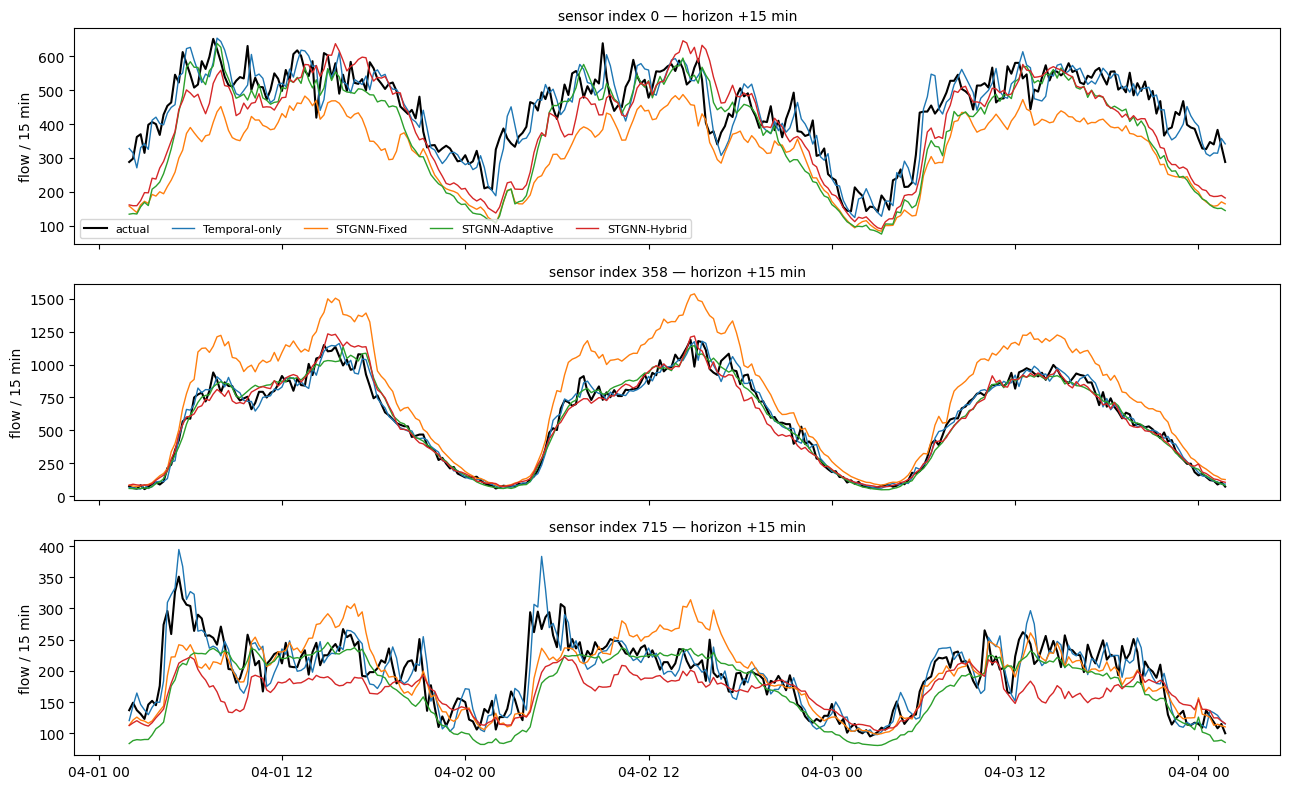

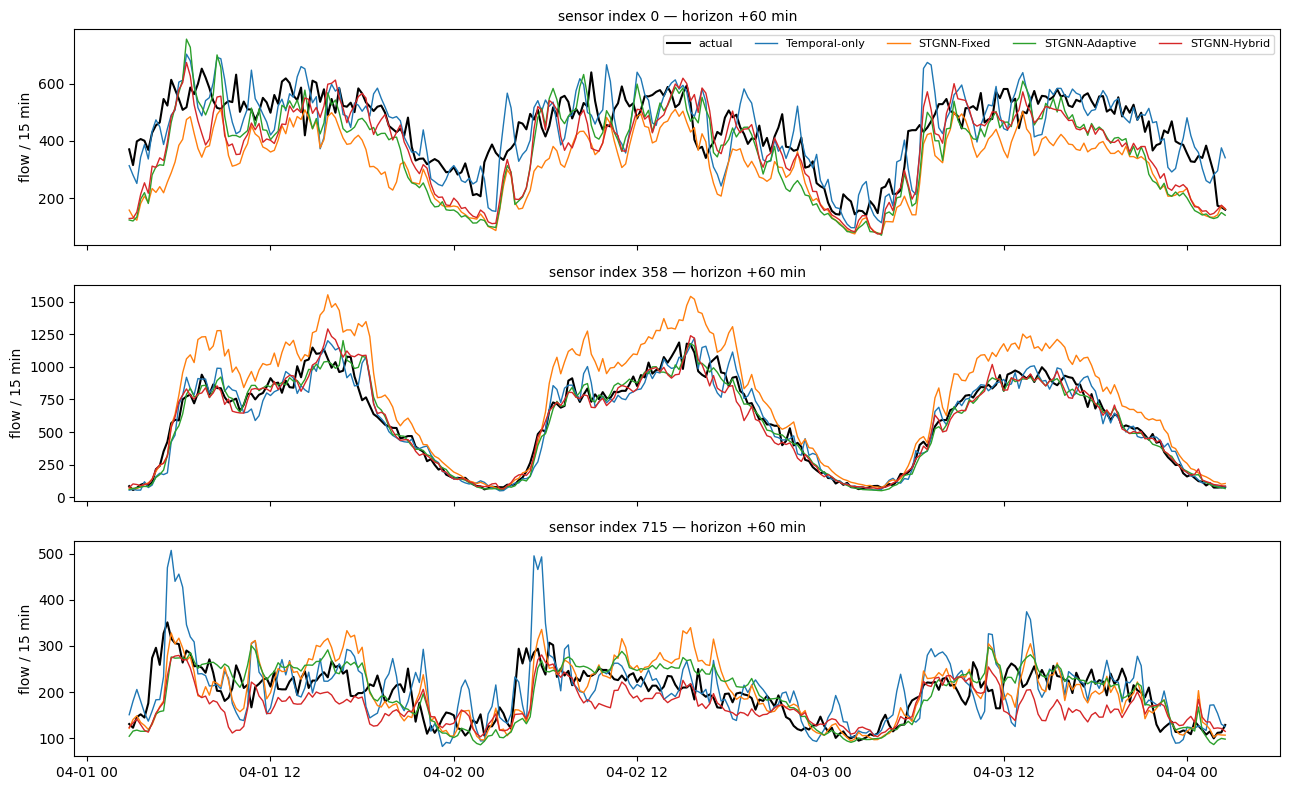

In [28]:
# predicted vs actual on the first 3 days of the test period, 3 sensors, horizons +15 min and +60 min
test_ts = results["Temporal-only"]["test"]["ts"]
n_show = 3 * 96
truth_all = (data_n[:, PLOT_SENSORS] * SD + MU).numpy()                       # (T, 3)
for h in (0, HORIZON - 1):
    fig, ax = plt.subplots(len(PLOT_SENSORS), 1, figsize=(13, 8), sharex=True)
    tt = test_ts[:n_show] + (h + 1)                                           # target time index
    for j, a in enumerate(ax):
        a.plot(times[tt], truth_all[tt, j], "k", lw=1.5, label="actual")
        for k, _ in rows:
            if k in results: a.plot(times[tt], results[k]["test"]["pred_plot"][:n_show, h, j], lw=1, label=k)
        a.set_ylabel("flow / 15 min"); a.set_title(f"sensor index {PLOT_SENSORS[j]} — horizon +{15*(h+1)} min", fontsize=10)
    ax[0].legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 9. Q6(b) — Learned graph analysis

Compares the strongest learned edges with the physical graph (1-hop / 2-hop, treating the road graph as undirected for this check) and with geographic distance (haversine, from sensor coordinates).

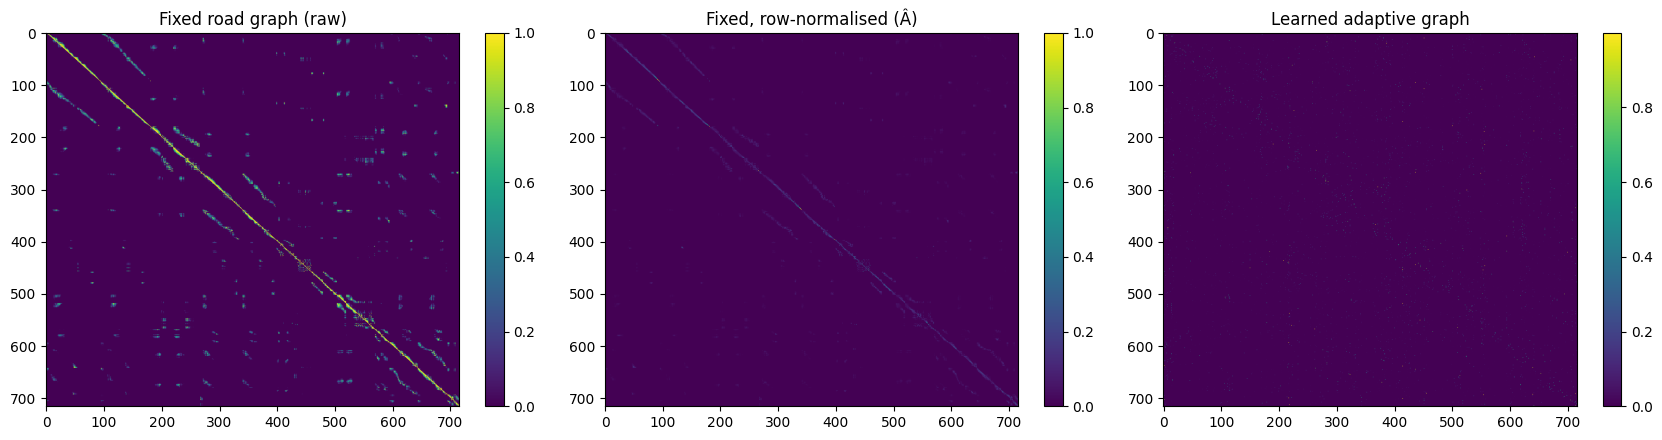

Top-10 learned edges per node: 7135 edges
  in road graph (1-hop): 0.057   | chance level (graph density): 0.0411
  within 2 hops        : 0.128   | chance level: 0.1008
median distance (km): learned 21.97 | physical edges 2.51 | all pairs 23.02


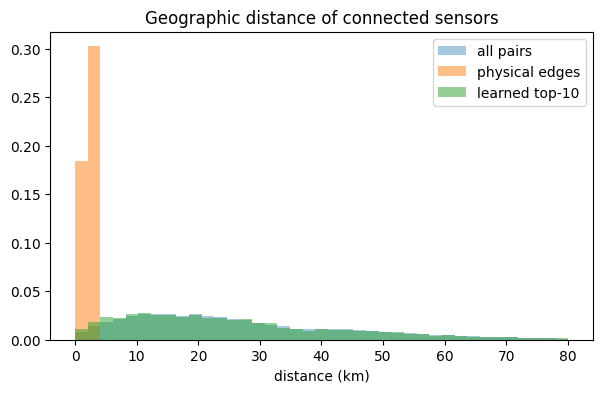

learned edges absent from the 2-hop physical graph: 6223 (87.2%)
hybrid alpha: 0.5


In [29]:
A_l = results["STGNN-Adaptive"]["adj"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, M, t in zip(ax, [A, normalize_fixed(A, force_row=True), A_l],
                   ["Fixed road graph (raw)", "Fixed, row-normalised (Â)", "Learned adaptive graph"]):
    im = a.imshow(M, cmap="viridis", aspect="auto"); a.set_title(t); plt.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

K_EVAL = 10
nbrs = np.argsort(-A_l, axis=1)[:, :K_EVAL]
rows_i = np.repeat(np.arange(N), K_EVAL); cols_j = nbrs.ravel()
keep_e = rows_i != cols_j; rows_i, cols_j = rows_i[keep_e], cols_j[keep_e]

A_und = (A_bin + A_bin.T) > 0
A_two = ((A_und.astype(np.int64) + A_und.astype(np.int64) @ A_und.astype(np.int64)) > 0); np.fill_diagonal(A_two, False)
pairs = N * (N - 1)
print(f"Top-{K_EVAL} learned edges per node: {len(rows_i)} edges")
print(f"  in road graph (1-hop): {A_und[rows_i, cols_j].mean():.3f}   | chance level (graph density): {A_und.sum()/pairs:.4f}")
print(f"  within 2 hops        : {A_two[rows_i, cols_j].mean():.3f}   | chance level: {A_two.sum()/pairs:.4f}")

# geographic distance
if {"Lat", "Lng"} <= set(meta.columns):
    lat, lng = np.radians(meta["Lat"].values), np.radians(meta["Lng"].values)
    dlat, dlng = lat[:, None] - lat[None, :], lng[:, None] - lng[None, :]
    h = np.sin(dlat / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlng / 2) ** 2
    D = 2 * 6371.0 * np.arcsin(np.sqrt(h))
    d_learn = D[rows_i, cols_j]
    ei, ej = np.nonzero(np.triu(A_und, 1)); d_fixed = D[ei, ej]
    iu = np.triu_indices(N, 1); d_all = D[iu]
    print(f"median distance (km): learned {np.median(d_learn):.2f} | physical edges {np.median(d_fixed):.2f} | all pairs {np.median(d_all):.2f}")
    plt.figure(figsize=(7, 4))
    bins = np.linspace(0, np.percentile(d_all, 99), 40)
    plt.hist(d_all, bins, density=True, alpha=0.4, label="all pairs")
    plt.hist(d_fixed, bins, density=True, alpha=0.5, label="physical edges")
    plt.hist(d_learn, bins, density=True, alpha=0.5, label=f"learned top-{K_EVAL}")
    plt.xlabel("distance (km)"); plt.legend(); plt.title("Geographic distance of connected sensors"); plt.show()

# learned edges that are NOT in the physical 2-hop graph: candidates for "new" dependencies
new_edges = ~A_two[rows_i, cols_j] & ~A_und[rows_i, cols_j]
print(f"learned edges absent from the 2-hop physical graph: {new_edges.sum()} ({new_edges.mean():.1%})")
if "alpha" in results.get("STGNN-Hybrid", {}): print("hybrid alpha:", results["STGNN-Hybrid"]["alpha"])

**Write in the report (own words), using the numbers above:** (1) overlap of strongest learned edges with the road graph vs chance; (2) whether learned edges are geographically close; (3) what the non-physical edges might represent (similar commuting patterns, same-corridor sensors on different roads); (4) why learned can be better (flexible, data-driven) or worse (noisy, overfits, no inductive prior, only 1 year of training data, softmax/top-k limitations).

### Q6(c) — Critical discussion (prompts for your own answer)
* Lower error ≠ true connectivity: the adjacency is just a set of free parameters that improves the loss; many different graphs can give similar error, and the model may use it to share *statistical* (e.g. time-of-day) patterns rather than physical flow.
* Why hybrid can win: the road graph is a strong prior that speeds learning and regularises; the learned part adds dependencies the road graph misses.
* Static graph limits: one matrix for all times of day, though dependencies change (rush hour, incidents, weekday vs weekend, direction of dominant flow). Ideas: time-dependent / attention-based adjacency, or time-conditioned embeddings.

## 10. Q7 — Reproducibility information

In [30]:
def ram_gb():
    try: return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9, 1)
    except Exception: return None

info = {
    "platform": platform.platform(), "processor": platform.processor(), "cpu_count": os.cpu_count(),
    "ram_gb": ram_gb(), "python": platform.python_version(), "torch": torch.__version__,
    "device": str(device), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED, "synthetic_data": SYNTHETIC,
    "hyperparameters": dict(AGG=AGG, FFILL_LIMIT=FFILL_LIMIT, HIST=HIST, HORIZON=HORIZON, HIDDEN=HIDDEN,
        EMB_DIM=EMB_DIM, TOPK=TOPK, HYBRID_ALPHA=HYBRID_ALPHA, HYBRID_LEARN_ALPHA=HYBRID_LEARN_ALPHA,
        BATCH=BATCH, EPOCHS=EPOCHS, LR=LR, PATIENCE=PATIENCE, optimizer="Adam", loss="L1 on normalised data"),
    "train_mean": MU, "train_std": SD,
}
summary = {k: {kk: vv for kk, vv in v.items() if kk in ("mode", "train_time_s", "epochs_run", "n_params", "alpha")}
           | {"val_mae": v["val"]["mae"], "val_rmse": v["val"]["rmse"],
              "test_mae": v["test"]["mae"], "test_rmse": v["test"]["rmse"]} for k, v in results.items()}
with open("results.json", "w") as f: json.dump({"environment": info, "results": summary}, f, indent=2)
print(json.dumps(info, indent=2))

{
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "cpu_count": 4,
  "ram_gb": 33.7,
  "python": "3.13.18",
  "torch": "2.11.0+cpu",
  "device": "cpu",
  "gpu": null,
  "seed": 42,
  "synthetic_data": false,
  "hyperparameters": {
    "AGG": "sum",
    "FFILL_LIMIT": 4,
    "HIST": 8,
    "HORIZON": 4,
    "HIDDEN": 32,
    "EMB_DIM": 16,
    "TOPK": 20,
    "HYBRID_ALPHA": 0.5,
    "HYBRID_LEARN_ALPHA": false,
    "BATCH": 128,
    "EPOCHS": 10,
    "LR": 0.001,
    "PATIENCE": 3,
    "optimizer": "Adam",
    "loss": "L1 on normalised data"
  },
  "train_mean": 588.53955078125,
  "train_std": 484.9562072753906
}


### Reproduction instructions (copy into your README / report)
1. Place LargeST files in `./data/ca` (or set `LARGEST_DIR`).
2. `pip install numpy pandas matplotlib torch tables jupyter`
3. `jupyter nbconvert --to notebook --execute assignment3.ipynb` (or run all cells). Seed = 42.
4. Outputs: `results_table.csv`, `results.json`, and the figures shown inline.

### AI-usage log (required by the course policy)
Record at the end of your report: the prompts you gave, the output you received, and the edits you made to this code.